# 14. Кластеризация временных рядов

Рабочий ноутбук к главе книги `../chapters/14-clustering.md`: здесь только задания и код, теория и выводы — в главе. Источник — глава 28 пособия.

Графики для главы сохраняй через `save_fig(fig, "имя")` → `../chapters/img/14-имя.png`.

In [1]:
import os
import warnings
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Глушим шум до импорта ETNA: FutureWarning из pandas и предупреждение tqdm про ipywidgets
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

from etna.datasets import TSDataset
from etna.transforms import StandardScalerTransform
from etna.clustering import EuclideanClustering, DTWClustering
from etna.analysis import plot_clusters

DATA_DIR = "../local/data"
IMG_DIR = "../chapters/img"  # графики для главы книги
RANDOM_SEED = 42


def save_fig(fig, name: str) -> None:
    """Сохранить график для главы книги: ../chapters/img/14-<name>.png."""
    os.makedirs(IMG_DIR, exist_ok=True)
    fig.savefig(f"{IMG_DIR}/14-{name}.png", dpi=150, bbox_inches="tight")

## Задание 1. Синтетика: найти группы

Ряды из групп, которые мы задали сами: совпадут ли кластеры с ними.

### Шаг 1.1. Ряды трёх форм

12 рядов: три формы по 4 ряда, и у каждой формы ряды разного масштаба — от 50 до 200 в среднем.

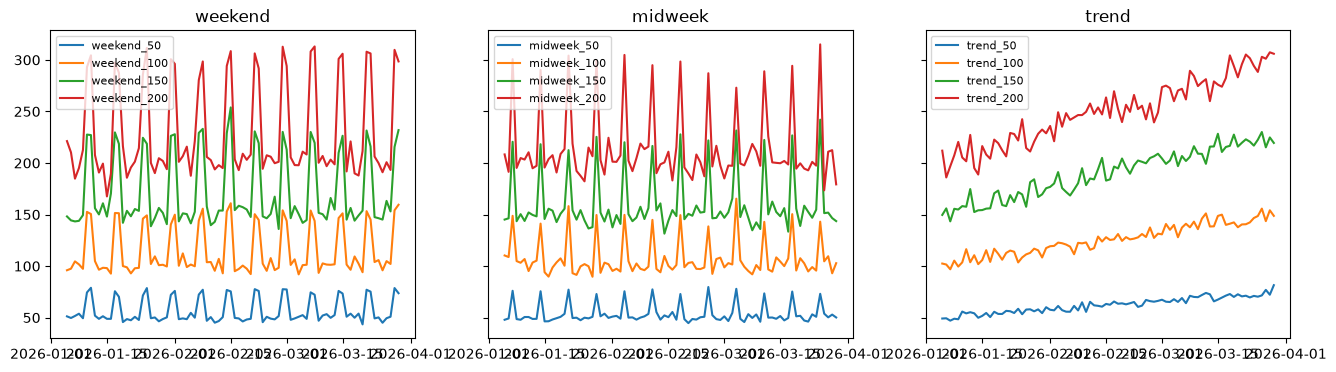

In [2]:
# 12 рядов трёх групп по 4, у каждой группы свой масштаб от маленького до большого:
#   weekend — пик в выходные, midweek — пик в среду, trend — недельного узора нет, ряд растёт
PERIODS = 12 * 7
LEVELS = [50, 100, 150, 200]
rng = np.random.RandomState(RANDOM_SEED)
t = np.arange(PERIODS)
timestamps = pd.date_range("2026-01-05", periods=PERIODS, freq="D")  # начинаем с понедельника
day_of_week = timestamps.dayofweek.values

SHAPES = {
    "weekend": lambda: np.where(day_of_week >= 5, 0.5, 0.0),
    "midweek": lambda: np.where(day_of_week == 2, 0.5, 0.0),
    "trend": lambda: 0.006 * t,
}
frames, true_group = [], {}
for group, shape in SHAPES.items():
    for level in LEVELS:
        segment = f"{group}_{level}"
        values = level * (1 + shape() + rng.normal(0, 0.05, PERIODS))
        frames.append(pd.DataFrame({"timestamp": timestamps, "segment": segment, "target": values}))
        true_group[segment] = group
ts = TSDataset(pd.concat(frames), freq="D")
true_group = pd.Series(true_group, name="true_group")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, group in zip(axes, SHAPES):
    for segment in true_group[true_group == group].index:
        ax.plot(timestamps, ts[:, segment, "target"].values, label=segment)
    ax.set_title(group)
    ax.legend(loc="upper left", fontsize=8)
save_fig(fig, "synthetic")

#### Выводы

- **Три формы:** `weekend` — пик в выходные (+50%), `midweek` — пик в среду (+50%), `trend` — недельного узора нет, ряд растёт на 50% за 12 недель.
- **Внутри каждой формы 4 масштаба:** 50, 100, 150 и 200 в среднем. Шум ±5% от уровня.
- Правильный ответ — 3 кластера по форме, масштаб значения не имеет.

### Шаг 1.2. Евклид по сырым рядам

`EuclideanClustering`: `build_distance_matrix` → `build_clustering_algo(n_clusters=3)` → `fit_predict`.

In [3]:
def cluster(ts: TSDataset, model, n_clusters: int = 3) -> pd.Series:
    """Кластеры рядов: матрица расстояний → иерархическая кластеризация."""
    model.build_distance_matrix(ts)
    model.build_clustering_algo(n_clusters=n_clusters, linkage="average")
    return pd.Series(model.fit_predict(), name="cluster")


def compare(true: pd.Series, clusters: dict) -> pd.DataFrame:
    """Таблица: настоящая группа и номер кластера у каждого способа."""
    return pd.concat([true, *[c.rename(name) for name, c in clusters.items()]], axis=1)


# Евклидово расстояние по сырым рядам
euclid_raw = cluster(ts, EuclideanClustering())
compare(true_group, {"euclid_raw": euclid_raw})

,true_group,euclid_raw
weekend_50,weekend,0
weekend_100,weekend,0
weekend_150,weekend,1
weekend_200,weekend,2
midweek_50,midweek,0
midweek_100,midweek,0
midweek_150,midweek,1
midweek_200,midweek,1
trend_50,trend,0
trend_100,trend,0


#### Выводы

- **Кластеры собрались по масштабу, а не по форме:** все ряды с уровнем 50–100 попали в кластер 0, независимо от формы.
- Евклидово расстояние — это разница значений день за днём. Ряд на 50 и ряд на 200 далеки всегда, даже с одинаковой формой.

### Шаг 1.3. Нормировка, Евклид и DTW

`StandardScalerTransform(mode="per-segment")` приводит каждый ряд к среднему 0 и разбросу 1. Потом — `EuclideanClustering` и `DTWClustering`.

In [4]:
# Тот же Евклид, но каждый ряд приведён к одному масштабу: среднее 0, разброс 1
ts_scaled = deepcopy(ts)
ts_scaled.fit_transform([StandardScalerTransform(in_column="target", mode="per-segment")])

euclid_scaled_model = EuclideanClustering()
euclid_scaled = cluster(ts_scaled, euclid_scaled_model)
dtw_scaled = cluster(ts_scaled, DTWClustering())
compare(true_group, {"euclid_raw": euclid_raw, "euclid_scaled": euclid_scaled, "dtw_scaled": dtw_scaled})

,true_group,euclid_raw,euclid_scaled,dtw_scaled
weekend_50,weekend,0,2,2
weekend_100,weekend,0,2,2
weekend_150,weekend,1,2,2
weekend_200,weekend,2,2,2
midweek_50,midweek,0,0,0
midweek_100,midweek,0,0,0
midweek_150,midweek,1,0,0
midweek_200,midweek,1,0,0
trend_50,trend,0,1,1
trend_100,trend,0,1,1


#### Выводы

- **После нормировки оба расстояния нашли все 3 группы без ошибок:** кластер 2 — `weekend`, 0 — `midweek`, 1 — `trend`.
- **Нормировка решает, по чему группировать:** без неё — по объёму, с ней — по форме.

### Шаг 1.4. Центроиды

`get_centroids` — «средний ряд» каждого кластера, `plot_clusters` рисует ряды кластера и центроид.

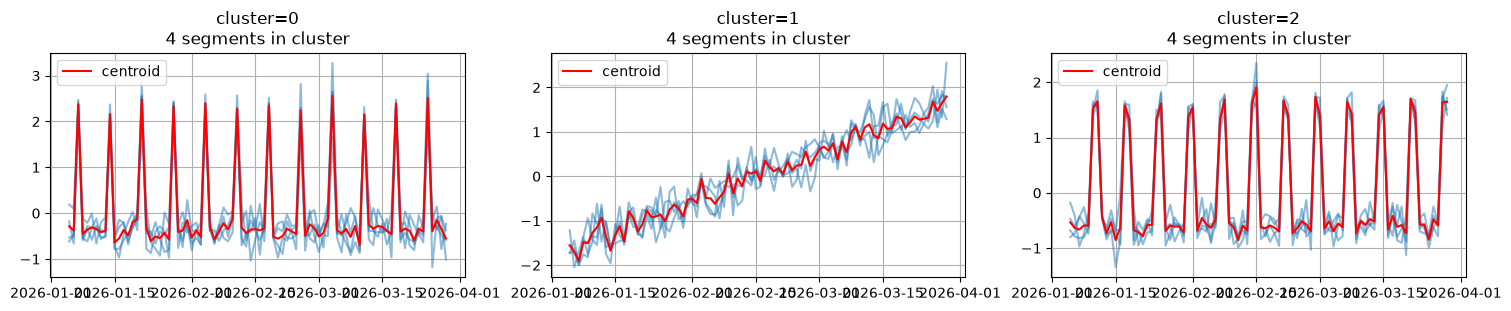

In [5]:
# Центроиды — «средний ряд» каждого кластера
centroids = euclid_scaled_model.get_centroids()
plot_clusters(ts_scaled, euclid_scaled_model.segment2cluster, centroids, columns_num=3, figsize=(5, 3))
save_fig(plt.gcf(), "centroids")

#### Выводы

- **Центроид — типичная форма кластера:** у кластеров видны пик в выходные, пик в среду и рост.
- По центроиду удобно описать кластер словами, не разглядывая каждый ряд.

### Шаг 1.5. Где DTW и Евклид расходятся

Две группы по 4 ряда с одинаковым узором, но пик у одной в среду, у другой в четверг. Нормированные ряды, 2 кластера.

In [6]:
# Где DTW и Евклид расходятся: узор один и тот же, но пик сдвинут на день — в среду или в четверг
frames_shift, true_shift = [], {}
for peak_day, name in [(2, "wednesday"), (3, "thursday")]:
    for level in LEVELS:
        segment = f"{name}_{level}"
        values = level * (1 + np.where(day_of_week == peak_day, 0.5, 0.0) + rng.normal(0, 0.05, PERIODS))
        frames_shift.append(pd.DataFrame({"timestamp": timestamps, "segment": segment, "target": values}))
        true_shift[segment] = name
ts_shift = TSDataset(pd.concat(frames_shift), freq="D")
ts_shift.fit_transform([StandardScalerTransform(in_column="target", mode="per-segment")])
true_shift = pd.Series(true_shift, name="true_group")

compare(true_shift, {
    "euclid_scaled": cluster(ts_shift, EuclideanClustering(), n_clusters=2),
    "dtw_scaled": cluster(ts_shift, DTWClustering(), n_clusters=2),
})

,true_group,euclid_scaled,dtw_scaled
wednesday_50,wednesday,1,0
wednesday_100,wednesday,1,0
wednesday_150,wednesday,1,0
wednesday_200,wednesday,1,0
thursday_50,thursday,0,1
thursday_100,thursday,0,0
thursday_150,thursday,0,1
thursday_200,thursday,0,0


#### Выводы

- **Евклид разделил группы без ошибок:** пик в среду и пик в четверг — это разные значения в одни и те же дни.
- **DTW перемешал группы:** он разрешает «сдвигать» ряды во времени, чтобы совместить похожие куски. Для него пик в среду и пик в четверг — одна и та же форма: расстояние между такими рядами без шума равно 0. Кластеры получились по случайному шуму.
- **DTW нужен, когда важна форма, а не точное время:** например, одинаковая реакция на акцию, начавшуюся в разные дни. Для недельного узора, где важен именно день, лучше Евклид.

## Задание 2. Кластеры наших юнитов

10 юнитов, по 2 каждого размера (`UnitSize`): совпадёт ли разбиение ETNA с размерами.

### Шаг 2.1. Загрузка

`facts-by-date.csv` с 2026-04-01 — с этой даты есть данные по всем 10 юнитам.

2026-04-01 — 2026-08-31, пропусков: 0


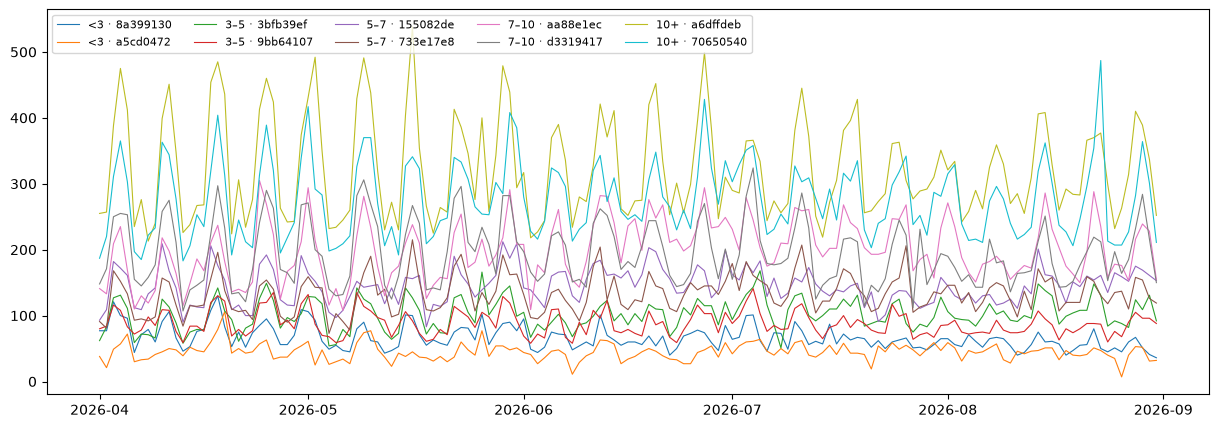

In [7]:
# 10 юнитов, по 2 из каждого размера (UnitSize); общий период — с 2026-04-01: два самых маленьких юнита открылись в конце марта
START = "2026-04-01"
units = pd.read_csv(f"{DATA_DIR}/units.csv")
facts = pd.read_csv(f"{DATA_DIR}/facts-by-date.csv", parse_dates=["CalendarDate"])
facts = facts[facts["CalendarDate"] >= START]
df_units = facts.rename(columns={"CalendarDate": "timestamp", "MaskedUnitId": "segment", "Fact": "target"})
ts_units = TSDataset(df_units, freq="D")
dates = ts_units.to_pandas().index

unit_size = units.set_index("MaskedUnitId")["UnitSize"].rename("unit_size")
SIZE_ORDER = ["<3", "3–5", "5–7", "7–10", "10+"]
unit_size = unit_size.loc[unit_size.map(SIZE_ORDER.index).sort_values().index]  # от маленьких к большим

print(f"{dates.min().date()} — {dates.max().date()}, пропусков: {int(ts_units.to_pandas().isna().sum().sum())}")
fig, ax = plt.subplots(figsize=(15, 5))
for segment in unit_size.index:
    ax.plot(dates, ts_units[:, segment, "target"].values, linewidth=0.8, label=f"{unit_size[segment]} · {segment}")
ax.legend(ncol=5, fontsize=8, loc="upper left")
save_fig(fig, "units")

#### Выводы

- **5 месяцев, 153 дня, пропусков нет.**
- **Юниты сильно различаются объёмом:** в среднем от 45 заказов в день у самого маленького до 323 у самого большого.
- **Недельный узор у всех похожий:** пики в пятницу и субботу.

### Шаг 2.2. Кластеры тремя способами

5 кластеров — столько же, сколько размеров: Евклид по сырым рядам, Евклид и DTW после нормировки.

In [8]:
# Кластеризуем на 5 групп — столько же, сколько размеров; три способа, как в синтетике
ts_units_scaled = deepcopy(ts_units)
ts_units_scaled.fit_transform([StandardScalerTransform(in_column="target", mode="per-segment")])

units_euclid_scaled_model = EuclideanClustering()
units_clusters = compare(unit_size, {
    "euclid_raw": cluster(ts_units, EuclideanClustering(), n_clusters=5),
    "euclid_scaled": cluster(ts_units_scaled, units_euclid_scaled_model, n_clusters=5),
    "dtw_scaled": cluster(ts_units_scaled, DTWClustering(), n_clusters=5),
})
units_clusters

,unit_size,euclid_raw,euclid_scaled,dtw_scaled
8a399130,<3,0,2,2
a5cd0472,<3,0,1,3
3bfb39ef,3–5,0,0,0
9bb64107,3–5,0,4,4
155082de,5–7,3,3,1
733e17e8,5–7,3,0,0
aa88e1ec,7–10,1,0,1
d3319417,7–10,1,0,4
a6dffdeb,10+,2,0,4
70650540,10+,4,0,4


#### Выводы

| размер | юниты | `euclid_raw` | `euclid_scaled` | `dtw_scaled` |
|---|---|---|---|---|
| `<3` | 8a399130, a5cd0472 | 0, 0 | 2, 1 | 2, 3 |
| `3–5` | 3bfb39ef, 9bb64107 | 0, 0 | 0, 4 | 0, 4 |
| `5–7` | 155082de, 733e17e8 | 3, 3 | 3, 0 | 1, 0 |
| `7–10` | aa88e1ec, d3319417 | 1, 1 | 0, 0 | 1, 4 |
| `10+` | a6dffdeb, 70650540 | 2, 4 | 0, 0 | 4, 4 |

- **Евклид по сырым рядам почти повторил размеры:** 4 пары из 5 оказались вместе. Ошибок две: `<3` и `3–5` слились в один кластер, а пара `10+` разделилась. Размер юнита — это объём заказов, а сырой Евклид группирует как раз по объёму.
- **Почему так:** расстояние растёт вместе с масштабом. Юниты `10+` (323 и 276 заказов в день) отличаются друг от друга сильнее, чем `<3` от `3–5` (45–102 заказа).
- **После нормировки размеры не угадываются:** 6 юнитов собрались в один большой кластер, остальные 4 — по одному. Масштаб убран, а по форме юниты почти одинаковы.

### Шаг 2.3. Смысл кластеров после нормировки

Чем отличаются юниты-одиночки от большого кластера: средний профиль недели и уровень по месяцам (доля от среднего юнита).

In [9]:
# Что общего у юнитов внутри кластера после нормировки: средний профиль недели (доля от среднего дня)
weekly = ts_units.to_pandas().droplevel("feature", axis=1)
weekly_profile = (weekly / weekly.mean()).groupby(weekly.index.dayofweek).mean().T
weekly_profile.columns = ["mon", "tue", "wed", "thu", "fri", "sat", "sun"]
weekly_profile.insert(0, "cluster", units_clusters["euclid_scaled"])
weekly_profile.insert(0, "unit_size", unit_size)
weekly_profile.loc[unit_size.index].round(2)

,unit_size,cluster,mon,tue,wed,thu,fri,sat,sun
MaskedUnitId,,,,,,,,,
8a399130,<3,2,0.80,0.90,0.90,0.93,1.25,1.22,1.00
a5cd0472,<3,1,0.80,0.91,0.86,0.93,1.15,1.20,1.14
3bfb39ef,3–5,0,0.82,0.87,0.85,0.90,1.22,1.23,1.10
9bb64107,3–5,4,0.82,0.89,0.87,0.94,1.24,1.18,1.04
155082de,5–7,3,0.88,0.91,0.89,0.94,1.19,1.11,1.07
733e17e8,5–7,0,0.85,0.86,0.87,0.91,1.20,1.20,1.11
aa88e1ec,7–10,0,0.84,0.86,0.88,0.89,1.19,1.27,1.07
d3319417,7–10,0,0.79,0.84,0.78,0.92,1.23,1.32,1.11
a6dffdeb,10+,0,0.80,0.83,0.81,0.88,1.23,1.31,1.13


In [10]:
# Как менялся уровень юнита по месяцам: доля от его среднего за весь период
monthly_profile = (weekly / weekly.mean()).groupby(weekly.index.to_period("M")).mean().T
monthly_profile.insert(0, "cluster", units_clusters["euclid_scaled"])
monthly_profile.insert(0, "unit_size", unit_size)
monthly_profile.loc[unit_size.index].round(2)

timestamp,unit_size,cluster,2026-04,2026-05,2026-06,2026-07,2026-08
MaskedUnitId,,,,,,,
8a399130,<3,2,1.18,1.06,0.95,0.97,0.84
a5cd0472,<3,1,1.08,0.99,0.91,1.08,0.94
3bfb39ef,3–5,0,0.93,1.02,0.96,1.05,1.04
9bb64107,3–5,4,1.06,1.03,0.96,1.01,0.93
155082de,5–7,3,0.97,0.99,1.08,0.96,1.00
733e17e8,5–7,0,0.91,1.03,0.99,1.07,1.00
aa88e1ec,7–10,0,0.88,0.96,1.10,1.09,0.98
d3319417,7–10,0,1.00,1.07,1.00,0.99,0.94
a6dffdeb,10+,0,1.01,1.06,0.99,0.97,0.97


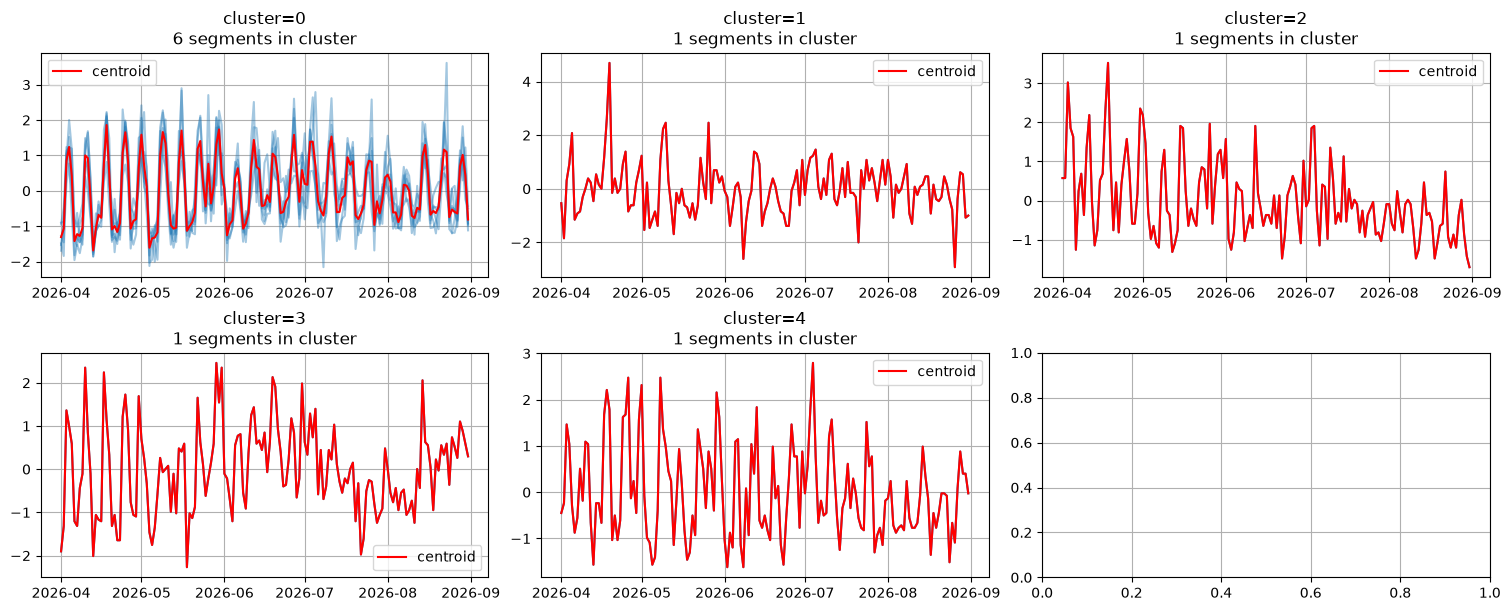

In [11]:
centroids_units = units_euclid_scaled_model.get_centroids()
plot_clusters(ts_units_scaled, units_euclid_scaled_model.segment2cluster, centroids_units, columns_num=3, figsize=(5, 3))
save_fig(plt.gcf(), "units-clusters")

In [12]:
# Чем одиночки отличаются от большого кластера:
#   corr_with_big — насколько юнит день за днём ходит вместе со «средним юнитом» большого кластера;
#   noise — разброс дня вокруг своего недельного профиля (доля от среднего);
#   weekend_lift — насколько пятница и суббота выше понедельника–четверга (доля от среднего)
share = weekly / weekly.mean()
day_profile = share.groupby(share.index.dayofweek).mean()
big_cluster = units_clusters["euclid_scaled"].value_counts().idxmax()
big_units = units_clusters.index[units_clusters["euclid_scaled"] == big_cluster]
scaled = (weekly - weekly.mean()) / weekly.std()

difference = pd.DataFrame({
    "unit_size": unit_size,
    "cluster": units_clusters["euclid_scaled"],
    "corr_with_big": scaled.corrwith(scaled[big_units].mean(axis=1)),
    "noise": (share - share.groupby(share.index.dayofweek).transform("mean")).std(),
    "weekend_lift": day_profile.loc[[4, 5]].mean() - day_profile.loc[[0, 1, 2, 3]].mean(),
})
difference.sort_values("corr_with_big").round(2)

,unit_size,cluster,corr_with_big,noise,weekend_lift
a5cd0472,<3,1,0.60,0.25,0.30
8a399130,<3,2,0.63,0.22,0.35
155082de,5–7,3,0.74,0.15,0.25
9bb64107,3–5,4,0.77,0.15,0.33
3bfb39ef,3–5,0,0.86,0.16,0.37
aa88e1ec,7–10,0,0.86,0.16,0.36
733e17e8,5–7,0,0.87,0.15,0.33
d3319417,7–10,0,0.90,0.15,0.44
70650540,10+,0,0.90,0.13,0.35
a6dffdeb,10+,0,0.91,0.12,0.44


#### Выводы

- **Недельный узор у всех юнитов почти одинаковый:** понедельник–четверг 0.8–0.9 от среднего дня, пятница–суббота 1.1–1.3. По форме недели юниты не делятся на группы.
- **Большой кластер (6 юнитов) — юниты, которые ходят синхронно:** их день за днём связывает с «средним юнитом» кластера корреляция 0.86–0.91. Это все `7–10` и `10+`, по одному из `3–5` и `5–7`.
- **Одиночки ходят «сами по себе»** — корреляция заметно ниже, 0.60–0.77:
  - `a5cd0472` и `8a399130` (оба `<3`) — самые шумные: дни отклоняются от своего недельного профиля на 22–25% против 12–16% у остальных. Плюс `8a399130` всё время теряет заказы: 1.18 от среднего в апреле, 0.84 в августе;
  - `155082de` (`5–7`) — самый слабый пик в выходные: пятница–суббота выше будней на 25% против 33–44% у остальных;
  - `9bb64107` (`3–5`) — по профилю и шуму обычный, но меньше совпадает с остальными по дням (0.77).
- **Итог:** кластеризация по сырым рядам нашла размеры, а по нормированным — «нетипичные» юниты. Оба ответа полезны, но отвечают на разные вопросы.